# 03 · Clustering de perfiles socioeducativos — ENAHO + ESCALE 2025

**Datos reales, sin nuevos archivos.** Este notebook continúa las fases 01 y 02, utiliza el **dataset maestro de 23.645 estudiantes** y produce perfiles mediante **K-Means y Gaussian Mixture Model (GMM)**. Compara valores de `k = 2, 3, 4, 5, 6` mediante **Silueta, Davies–Bouldin y Calinski–Harabasz**. Genera PCA 2D y gráficos, y agrega `CLUSTER_PERFIL` al **mismo maestro**.

**Orden:** terminar 01 y 02; colocar este `.ipynb` en `notebooks/`; abrirlo en Jupyter y elegir **Kernel → Restart & Run All**. Este notebook es **exploratorio**: `CLUSTER_PERFIL` **NO** se debe usar como predictor del modelo supervisado si se obtuvo ajustando el clustering sobre todo el dataset. El train/test futuro se separará por `CONGLOME` y preprocesará dentro de los folds.

**Precaución:** las variables ESCALE son promedios por distrito, no características del colegio concreto de la persona encuestada. Las categorías TIC y lengua se conservan como códigos operativos; revisar diccionarios oficiales antes de presentar interpretaciones sustantivas. No existe un indicador de altitud en estos seis archivos.

## Paso 1 — Encontrar el maestro y verificar que la fase 02 terminó

Comprobamos que existen las columnas clave, la etiqueta del rezago y los códigos de identificación; no alteramos los ceros a la izquierda.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

SEMILLA = 42
cwd = Path.cwd().resolve()
candidatos = []
for base in (cwd, *cwd.parents):
    candidatos += [base, base / 'proyecto_brecha_digital_2025']
ROOT = next((x for x in candidatos if (x / 'data' / 'processed' /
   'dataset_enaho_escale_2025.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('No encuentro data/processed/dataset_enaho_escale_2025.csv. '
                            'Abre este notebook dentro de notebooks/ y termina los pasos 01 y 02.')
RUTA = ROOT / 'data' / 'processed' / 'dataset_enaho_escale_2025.csv'
REP = ROOT / 'reportes'
FIG = REP / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
LLAVES = ['AÑO', 'CONGLOME', 'VIVIENDA', 'HOGAR', 'CODPERSO', 'UBIGEO']
# Conserva las llaves como texto sin perder los ceros a la izquierda.
df = pd.read_csv(RUTA, dtype={c: 'string' for c in LLAVES},
                 encoding='utf-8-sig', low_memory=False)
required = LLAVES + ['REZAGO_ESCOLAR', 'INGRESO_POR_MIEMBRO',
 'GASTO_POR_MIEMBRO', 'ESCALE_DIST_RATIO_ALUMNOS_DOCENTE',
 'ESCALE_DIST_PROP_PUBLICOS', 'ESCALE_DIST_N_COLEGIOS',
 'POBREZA','AREA_OPERATIVA_ENAHO', 'INTERNET_HOGAR',
 'ELECTRICIDAD_HOGAR', 'USO_INTERNET_MES', 'P300A']
faltantes = [v for v in required if v not in df.columns]
if faltantes:
    raise ValueError('Faltan columnas: ' + ', '.join(faltantes) +
     '. Ejecuta primero el notebook 02 sobre el maestro generado en 01.')
assert df['AÑO'].astype('string').eq('2025').all(), 'El archivo incluye años no deseados.'
assert df[LLAVES].notna().all().all(), 'Existen identificadores nulos.'
assert not df.duplicated(LLAVES).any(), 'El maestro presenta personas duplicadas.'
assert df['UBIGEO'].str.len().eq(6).all(), 'Se perdieron ceros de UBIGEO.'
assert df['REZAGO_ESCOLAR'].notna().sum() > 0, 'Aún no se ejecutó la fase 02.'
print('✓ Proyecto:', ROOT)
print('✓ Maestro cargado:', df.shape)
print('✓ Etiquetas de rezago:', df['REZAGO_ESCOLAR'].notna().sum())
print('✓ Duplicados:', df.duplicated(LLAVES).sum())

✓ Proyecto: C:\Users\Russbell\Downloads\inteligenciaartificial\datamodulos\data_limpia
✓ Maestro cargado: (23645, 81)
✓ Etiquetas de rezago: 17249
✓ Duplicados: 0


## Paso 2 — Seleccionar variables sin usar el objetivo

El conjunto de variables describe **condiciones socioeconómicas, uso reportado de TIC y contexto escolar distrital**. No se incluyen el rezago, su edad normativa, las llaves personales ni `FACTOR07` como predictoras.

- Las tres magnitudes de ingreso/gasto/cantidad de instituciones se transforman con `log1p` para atenuar valores extremos; no se borran estudiantes.
- Los códigos categóricos se tratan como **categorías, no cantidades**. La lengua `P300A` se agrupa en los dos códigos más frecuentes y `OTROS_CODIGOS`, sin inventar traducciones.
- La imputación de faltantes es **exclusivamente exploratoria** en esta etapa. En clasificación debe repetirse dentro de cada fold usando `Pipeline`/`GroupKFold`.

In [2]:
NUMERICAS = ['INGRESO_POR_MIEMBRO', 'GASTO_POR_MIEMBRO',
 'ESCALE_DIST_RATIO_ALUMNOS_DOCENTE', 'ESCALE_DIST_PROP_PUBLICOS',
 'ESCALE_DIST_N_COLEGIOS']
CATEGORICAS = ['POBREZA', 'AREA_OPERATIVA_ENAHO', 'INTERNET_HOGAR',
 'ELECTRICIDAD_HOGAR', 'USO_INTERNET_MES', 'P300A_AGRUPADA']
Xraw = df[[c for c in NUMERICAS if c in df.columns]].copy()
for c in NUMERICAS:
    Xraw[c] = pd.to_numeric(Xraw[c], errors='coerce')
for c in ['INGRESO_POR_MIEMBRO','GASTO_POR_MIEMBRO','ESCALE_DIST_N_COLEGIOS']:
    n_neg = int((Xraw[c] < 0).sum())
    if n_neg: warnings.warn(f'{c}: {n_neg} valores negativos pasan a NaN antes de log1p.')
    Xraw[c] = np.log1p(Xraw[c].where(Xraw[c] >= 0))
for c in CATEGORICAS:
    if c != 'P300A_AGRUPADA':
        Xraw[c] = df[c].astype('string').str.replace(r'\.0$', '', regex=True).fillna('SIN_DATO')
lengua = df['P300A'].astype('string').str.replace(r'\.0$', '', regex=True).fillna('SIN_DATO')
frecuentes = lengua.value_counts().head(2).index.tolist()
Xraw['P300A_AGRUPADA'] = lengua.where(lengua.isin(frecuentes), 'OTROS_CODIGOS')
Xraw[CATEGORICAS] = Xraw[CATEGORICAS].astype(str)
print('✓ Variables numéricas:', NUMERICAS)
print('✓ Variables categóricas:', CATEGORICAS)
print('✓ Códigos P300A conservados como frecuentes:', frecuentes)
print('✓ Estudiantes a perfilar:', len(Xraw))
print('✓ Valores faltantes (antes de imputación):')
display(Xraw.isna().sum().sort_values(ascending=False).to_frame('NULOS'))

✓ Variables numéricas: ['INGRESO_POR_MIEMBRO', 'GASTO_POR_MIEMBRO', 'ESCALE_DIST_RATIO_ALUMNOS_DOCENTE', 'ESCALE_DIST_PROP_PUBLICOS', 'ESCALE_DIST_N_COLEGIOS']
✓ Variables categóricas: ['POBREZA', 'AREA_OPERATIVA_ENAHO', 'INTERNET_HOGAR', 'ELECTRICIDAD_HOGAR', 'USO_INTERNET_MES', 'P300A_AGRUPADA']
✓ Códigos P300A conservados como frecuentes: ['4', '1']
✓ Estudiantes a perfilar: 23645
✓ Valores faltantes (antes de imputación):


,NULOS
INGRESO_POR_MIEMBRO,0
GASTO_POR_MIEMBRO,0
ESCALE_DIST_RATIO_ALUMNOS_DOCENTE,0
ESCALE_DIST_PROP_PUBLICOS,0
ESCALE_DIST_N_COLEGIOS,0
POBREZA,0
AREA_OPERATIVA_ENAHO,0
INTERNET_HOGAR,0
ELECTRICIDAD_HOGAR,0
USO_INTERNET_MES,0


## Paso 3 — Imputación, escalado robusto y codificación

El procesamiento es reproducible, no requiere datos externos y **no crea una nueva tabla maestra**. Para clustering descriptivo se ajusta a todos los registros; el modelo predictivo de la siguiente fase debe usar un pipeline separado dentro de cada fold.

In [3]:
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False, dtype=np.float32)
preprocesador = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), NUMERICAS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', ohe)
    ]), CATEGORICAS)
], remainder='drop', sparse_threshold=0)
X = np.asarray(preprocesador.fit_transform(Xraw), dtype=np.float32)
assert X.shape[0] == len(df)
assert np.isfinite(X).all(), 'Existen valores no finitos después del preprocesamiento.'
print('✓ Matriz numérica para clustering:', X.shape)
print('✓ Todas las entradas finitas:', np.isfinite(X).all())

✓ Matriz numérica para clustering: (23645, 20)
✓ Todas las entradas finitas: True


## Paso 4 — Comparar dos métodos y justificar el número k

Evaluamos **K-Means** y **GMM (covarianza diagonal)** para k de 2 a 6, con `random_state=42`. Las métricas se calculan sobre **la misma muestra de hasta 2.000 estudiantes** para agilizar Jupyter. El ajuste y las etiquetas se obtienen en todo el dataset. Se rechazan como candidatas principales las soluciones con algún grupo menor del 2 % (para evitar perfiles de apenas unos estudiantes). La selección prioriza Silueta alta; Davies–Bouldin baja actúa como desempate. Calinski–Harabasz se reporta también. Los resultados descriptivos no constituyen validación de predicción.

In [4]:
rng = np.random.default_rng(SEMILLA)
idx_eval = np.sort(rng.choice(len(df), size=min(2000, len(df)), replace=False))
X_eval = X[idx_eval]
resultados = []
mejor = None
for metodo in ['KMeans', 'GMM']:
    for k in range(2, 7):
        if metodo == 'KMeans':
            modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
            etiquetas = modelo.fit_predict(X)
        else:
            modelo = GaussianMixture(n_components=k, covariance_type='diag',
                   reg_covar=1e-4, n_init=2, max_iter=150, random_state=SEMILLA)
            etiquetas = modelo.fit_predict(X)
        n_grupos = len(np.unique(etiquetas))
        fraccion_min = float(pd.Series(etiquetas).value_counts(normalize=True).min())
        et_eval = etiquetas[idx_eval]
        validas = 1 < len(np.unique(et_eval)) < len(et_eval)
        sil = float(silhouette_score(X_eval, et_eval)) if validas else np.nan
        db = float(davies_bouldin_score(X_eval, et_eval)) if validas else np.nan
        ch = float(calinski_harabasz_score(X_eval, et_eval)) if validas else np.nan
        resultados.append({'METODO':metodo, 'K':k, 'SILUETA':sil,
             'DAVIES_BOULDIN':db, 'CALINSKI_HARABASZ':ch,
             'GRUPOS_REALES':n_grupos, 'MIN_PROPORCION':fraccion_min,
             'CANDIDATO_ESTABLE': bool(validas and n_grupos==k and fraccion_min >= .02)})
        print(f'{metodo:6} k={k}: Sil={sil:.3f}, DB={db:.3f}, '
              f'CH={ch:.0f}, menor grupo={fraccion_min:.1%}')
res = pd.DataFrame(resultados)
validos = res.loc[res['CANDIDATO_ESTABLE'] & res['SILUETA'].notna()].copy()
if validos.empty:
    raise RuntimeError('Ningún método produjo k grupos de tamaño suficiente. '
                       'Revisar el preprocesamiento y las métricas; no se asignan perfiles.')
seleccion = validos.sort_values(['SILUETA','DAVIES_BOULDIN'], ascending=[False, True]).iloc[0]
METODO = str(seleccion['METODO'])
K = int(seleccion['K'])
print('\n✓ Método seleccionado:', METODO, '| k =', K,
      '| Silueta:', round(float(seleccion['SILUETA']), 3))
res.to_csv(REP / '03_comparacion_clustering_2025.csv', index=False, encoding='utf-8-sig')
display(res.round(4))

KMeans k=2: Sil=0.272, DB=1.506, CH=808, menor grupo=41.3%
KMeans k=3: Sil=0.238, DB=1.571, CH=606, menor grupo=17.3%
KMeans k=4: Sil=0.242, DB=1.600, CH=543, menor grupo=15.0%
KMeans k=5: Sil=0.185, DB=1.671, CH=495, menor grupo=15.0%
KMeans k=6: Sil=0.188, DB=1.735, CH=436, menor grupo=6.2%
GMM    k=2: Sil=0.220, DB=2.163, CH=287, menor grupo=20.2%
GMM    k=3: Sil=0.181, DB=1.781, CH=390, menor grupo=16.3%
GMM    k=4: Sil=0.230, DB=1.711, CH=475, menor grupo=14.9%
GMM    k=5: Sil=0.193, DB=1.764, CH=408, menor grupo=7.5%
GMM    k=6: Sil=0.192, DB=2.043, CH=346, menor grupo=7.1%

✓ Método seleccionado: KMeans | k = 2 | Silueta: 0.272


,METODO,K,SILUETA,DAVIES_BOULDIN,CALINSKI_HARABASZ,GRUPOS_REALES,MIN_PROPORCION,CANDIDATO_ESTABLE
0,KMeans,2,0.2721,1.5058,807.9007,2,0.4133,True
1,KMeans,3,0.2377,1.5705,605.7986,3,0.1734,True
2,KMeans,4,0.2424,1.6003,542.7100,4,0.1500,True
3,KMeans,5,0.1851,1.6707,495.3199,5,0.1500,True
4,KMeans,6,0.1877,1.7349,435.5213,6,0.0618,True
5,GMM,2,0.2200,2.1634,286.7467,2,0.2022,True
6,GMM,3,0.1808,1.7810,390.1540,3,0.1625,True
7,GMM,4,0.2305,1.7105,475.1611,4,0.1492,True
8,GMM,5,0.1926,1.7644,408.0379,5,0.0748,True
9,GMM,6,0.1916,2.0427,345.5221,6,0.0715,True


## Paso 5 — Ajustar el método ganador y visualizar métricas

Volvemos a ajustar el método elegido con la misma semilla y todos los registros. Esto garantiza que la tabla final usa exactamente la configuración reportada.

Grupos finales:
0    13872
1     9773


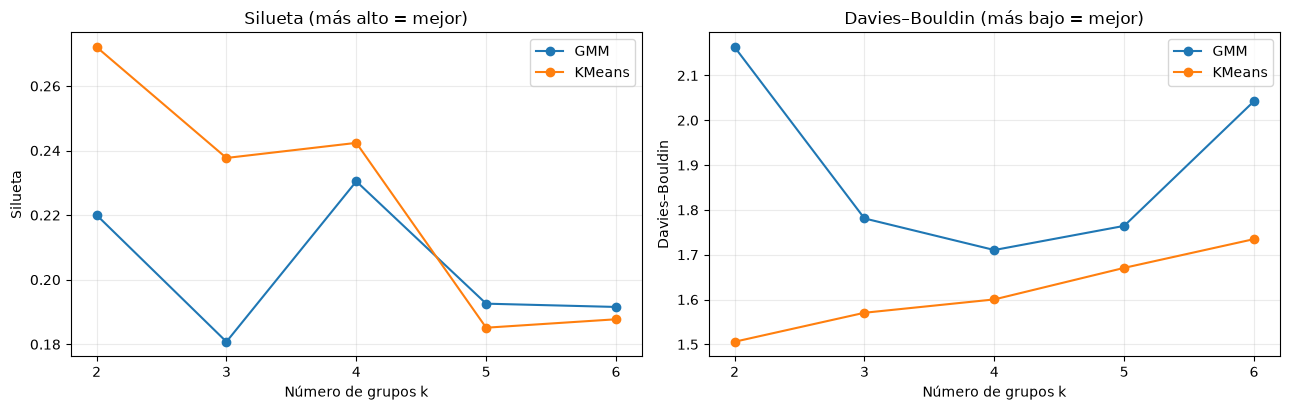

In [5]:
if METODO == 'KMeans':
    modelo_final = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA)
else:
    modelo_final = GaussianMixture(n_components=K, covariance_type='diag',
                  reg_covar=1e-4, n_init=2, max_iter=150, random_state=SEMILLA)
clusters = modelo_final.fit_predict(X).astype(int)
assert len(clusters) == len(df)
print('Grupos finales:')
print(pd.Series(clusters).value_counts().sort_index().to_string())
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for metodo, t in res.groupby('METODO'):
    axs[0].plot(t['K'], t['SILUETA'], marker='o', label=metodo)
    axs[1].plot(t['K'], t['DAVIES_BOULDIN'], marker='o', label=metodo)
axs[0].set(title='Silueta (más alto = mejor)', xlabel='Número de grupos k', ylabel='Silueta')
axs[1].set(title='Davies–Bouldin (más bajo = mejor)', xlabel='Número de grupos k', ylabel='Davies–Bouldin')
for a in axs:
    a.set_xticks(range(2,7)); a.grid(alpha=.25); a.legend()
fig.tight_layout()
fig.savefig(FIG / '03_metricas_clustering.png', dpi=180, bbox_inches='tight')
plt.show()

## Paso 6 — Proyección PCA bidimensional y siluetas por grupo

PCA sirve **para visualizar**, no para elegir perfiles por apariencia. La silueta por estudiante muestra separación y solapamiento de los grupos del método ganador, en la misma muestra de evaluación.

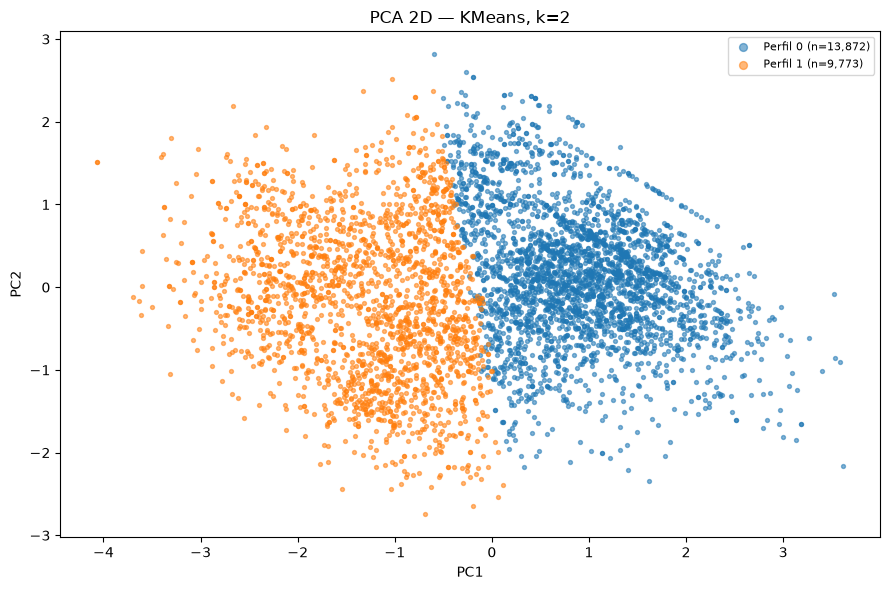

Varianza explicada por PC1 y PC2: 0.59


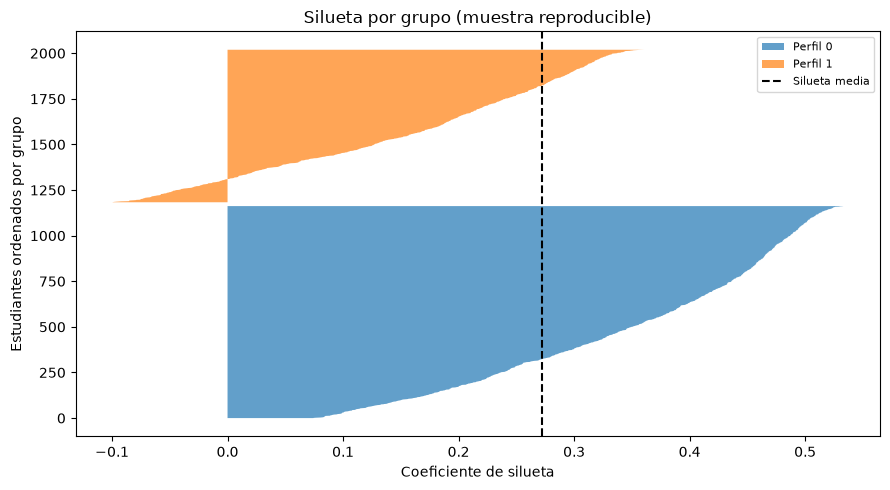

In [6]:
pca = PCA(n_components=2, random_state=SEMILLA)
coords = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(9, 6))
sub = np.sort(rng.choice(len(df), size=min(5000, len(df)), replace=False))
for cl in range(K):
    mask = clusters[sub] == cl
    ax.scatter(coords[sub[mask], 0], coords[sub[mask], 1], s=8, alpha=.55,
               label=f'Perfil {cl} (n={sum(clusters==cl):,})')
ax.set(title=f'PCA 2D — {METODO}, k={K}', xlabel='PC1', ylabel='PC2')
ax.legend(markerscale=2, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / '03_pca_perfiles.png', dpi=180, bbox_inches='tight')
plt.show()
print('Varianza explicada por PC1 y PC2:', round(float(pca.explained_variance_ratio_.sum()), 3))

sil_individual = silhouette_samples(X_eval, clusters[idx_eval])
fig, ax = plt.subplots(figsize=(9, 5))
y0 = 0
for cl in range(K):
    valores = np.sort(sil_individual[clusters[idx_eval] == cl])
    ys = np.arange(y0, y0 + len(valores))
    ax.fill_betweenx(ys, 0, valores, alpha=.7, label=f'Perfil {cl}')
    y0 += len(valores) + 20
ax.axvline(sil_individual.mean(), linestyle='--', color='black', label='Silueta media')
ax.set(title='Silueta por grupo (muestra reproducible)',
       xlabel='Coeficiente de silueta', ylabel='Estudiantes ordenados por grupo')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / '03_siluetas.png', dpi=180, bbox_inches='tight')
plt.show()

## Paso 7 — Interpretar los perfiles sin inventar rasgos

Se calculan medianas y proporciones por grupo, incluida la distribución de rezago únicamente como **descripción posterior**, nunca como entrada al clustering. Las proporciones son de la **muestra sin ponderar** (no tasas nacionales). Las cifras de escuelas/docentes corresponden a agregados distritales ESCALE y no identifican el colegio del encuestado.

Tabla de perfiles (códigos TIC requieren contrastación con el diccionario):


,CLUSTER_PERFIL,N_ESTUDIANTES,INGRESO_MIEMBRO_MEDIANA,GASTO_MIEMBRO_MEDIANA,RATIO_ALUMNOS_DOCENTE,PROP_COLEGIOS_PUBLICOS,PROP_AREA_RURAL,PROP_POBREZA_1_2,PROP_INTERNET_HOGAR,PROP_USO_INTERNET,PROP_ELECTRICIDAD,PROP_REZAGO_ETIQUETADOS,N_REZAGO_ETIQUETADOS,PORCENTAJE_MUESTRA
0,0,13872,10065.542,8487.306,17.425,0.555,0.067,0.155,0.981,0.852,0.986,0.404,10189,58.67
1,1,9773,4626.199,4349.823,11.789,0.939,0.788,0.513,0.911,0.551,0.832,0.424,7060,41.33


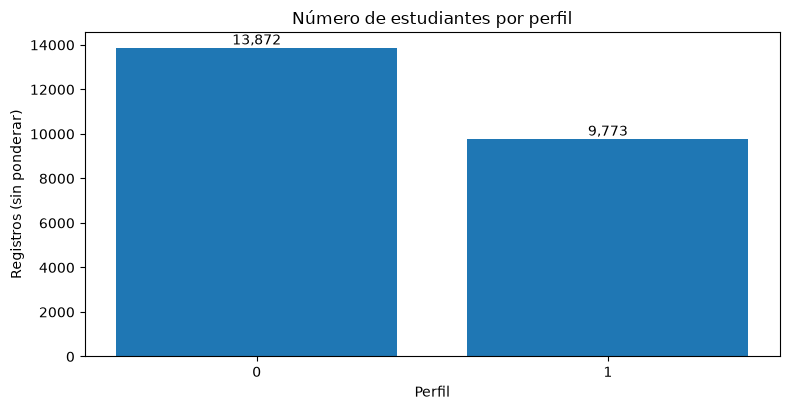

In [7]:
tmp = df.copy()
tmp['CLUSTER_PERFIL'] = clusters
for c in ['INGRESO_POR_MIEMBRO', 'GASTO_POR_MIEMBRO',
          'ESCALE_DIST_RATIO_ALUMNOS_DOCENTE', 'ESCALE_DIST_PROP_PUBLICOS',
          'INTERNET_HOGAR', 'ELECTRICIDAD_HOGAR', 'USO_INTERNET_MES',
          'REZAGO_ESCOLAR']:
    tmp[c] = pd.to_numeric(tmp[c], errors='coerce')
tmp['AREA_RURAL_OPERATIVA'] = pd.to_numeric(tmp['AREA_OPERATIVA_ENAHO'], errors='coerce').eq(2).astype(int)
tmp['POBREZA_1_O_2'] = pd.to_numeric(tmp['POBREZA'], errors='coerce').isin([1,2]).astype(int)
perfil = tmp.groupby('CLUSTER_PERFIL', sort=True).agg(
    N_ESTUDIANTES=('CLUSTER_PERFIL','size'),
    INGRESO_MIEMBRO_MEDIANA=('INGRESO_POR_MIEMBRO','median'),
    GASTO_MIEMBRO_MEDIANA=('GASTO_POR_MIEMBRO','median'),
    RATIO_ALUMNOS_DOCENTE=('ESCALE_DIST_RATIO_ALUMNOS_DOCENTE','median'),
    PROP_COLEGIOS_PUBLICOS=('ESCALE_DIST_PROP_PUBLICOS','mean'),
    PROP_AREA_RURAL=('AREA_RURAL_OPERATIVA','mean'),
    PROP_POBREZA_1_2=('POBREZA_1_O_2','mean'),
    PROP_INTERNET_HOGAR=('INTERNET_HOGAR','mean'),
    PROP_USO_INTERNET=('USO_INTERNET_MES','mean'),
    PROP_ELECTRICIDAD=('ELECTRICIDAD_HOGAR','mean'),
    PROP_REZAGO_ETIQUETADOS=('REZAGO_ESCOLAR','mean'),
    N_REZAGO_ETIQUETADOS=('REZAGO_ESCOLAR','count'),
).reset_index()
perfil['PORCENTAJE_MUESTRA'] = (perfil['N_ESTUDIANTES'] / len(tmp) * 100).round(2)
perfil.to_csv(REP / '03_perfiles_caracterizacion_2025.csv', index=False, encoding='utf-8-sig')
print('Tabla de perfiles (códigos TIC requieren contrastación con el diccionario):')
display(perfil.round(3))
fig, ax=plt.subplots(figsize=(8, 4.2))
ax.bar(perfil['CLUSTER_PERFIL'].astype(str), perfil['N_ESTUDIANTES'])
ax.set(title='Número de estudiantes por perfil', xlabel='Perfil', ylabel='Registros (sin ponderar)')
for i, n in enumerate(perfil['N_ESTUDIANTES']):
    ax.text(i, n, f'{n:,}', va='bottom', ha='center')
fig.tight_layout()
fig.savefig(FIG / '03_tamano_perfiles.png', dpi=180, bbox_inches='tight')
plt.show()

## Paso 8 — Guardar el cluster en el ÚNICO maestro + informe de control

Solo agregamos/actualizamos `CLUSTER_PERFIL` y dejamos el archivo maestro en su ruta original. No exportamos otro dataset maestro. Se guardan **tablas resumidas y gráficas** en `reportes/`. **Precaución contra fugas:** en el notebook supervisado 04 excluir `CLUSTER_PERFIL` y todas las columnas de objetivo/llaves; nunca usar clusters ajustados sobre test como predictores.

In [8]:
assert len(df) == 23645, 'Cambio inesperado en población respecto de los controles anteriores.'
assert df.duplicated(LLAVES).sum() == 0
assert set(pd.Series(clusters).unique()) == set(range(K))
df['CLUSTER_PERFIL'] = clusters

# Escritura atómica del maestro, para evitar dejarlo truncado si falla el proceso.
temporal = RUTA.with_name(RUTA.stem + '_temporal.csv')
try:
    df.to_csv(temporal, index=False, encoding='utf-8-sig')
    temporal.replace(RUTA)
finally:
    if temporal.exists(): temporal.unlink()
try:
    df.to_parquet(RUTA.with_suffix('.parquet'), index=False)
    print('✓ Parquet actualizado')
except (ImportError, TypeError, ValueError) as e:
    print('Aviso: Parquet no actualizado (opcional):', str(e)[:100])
reporte = {
 'fase':'03_clustering_exploratorio', 'anio':2025, 'semilla':SEMILLA,
 'metodos_comparados':['KMeans','GMM'], 'k_comparados':list(range(2,7)),
 'seleccion':{'metodo':METODO, 'k':K, 'silueta_muestra':float(seleccion['SILUETA']),
              'davies_bouldin_muestra':float(seleccion['DAVIES_BOULDIN']),
              'calinski_harabasz_muestra':float(seleccion['CALINSKI_HARABASZ'])},
 'registros':int(len(df)), 'columnas':int(len(df.columns)),
 'duplicados_personas':int(df.duplicated(LLAVES).sum()),
 'tamanos_cluster':{str(k):int(v) for k,v in pd.Series(clusters).value_counts().sort_index().items()},
 'muestra_metricas':int(len(idx_eval)),
 'predictores_numericos':NUMERICAS, 'predictores_categoricos':CATEGORICAS,
 'prohibido_en_supervisado':['CLUSTER_PERFIL','REZAGO_ESCOLAR','GRADO_EBR','EDAD_NORMATIVA','EDAD',
                             'P308A','P308B','P308C','CONGLOME','UBIGEO','CODPERSO'],
 'advertencia':'Clustering descriptivo de datos completos, sin uso como predictor en evaluación supervisada. '
               'Variables TIC deben contrastarse con diccionarios oficiales. Sin ponderaciones muestrales.'
}
(REP / '03_control_clustering_2025.json').write_text(
    json.dumps(reporte, ensure_ascii=False, indent=2), encoding='utf-8')
print('✓ Dataset maestro actualizado:', RUTA)
print('✓ Control:', REP / '03_control_clustering_2025.json')
print('✓ Comparación:', REP / '03_comparacion_clustering_2025.csv')
print('✓ Caracterización:', REP / '03_perfiles_caracterizacion_2025.csv')
print('✓ Gráficas:', FIG)
print('✓ Dimensión final:', df.shape)
print('✓ Cero duplicados:', df.duplicated(LLAVES).sum() == 0)

✓ Parquet actualizado
✓ Dataset maestro actualizado: C:\Users\Russbell\Downloads\inteligenciaartificial\datamodulos\data_limpia\data\processed\dataset_enaho_escale_2025.csv
✓ Control: C:\Users\Russbell\Downloads\inteligenciaartificial\datamodulos\data_limpia\reportes\03_control_clustering_2025.json
✓ Comparación: C:\Users\Russbell\Downloads\inteligenciaartificial\datamodulos\data_limpia\reportes\03_comparacion_clustering_2025.csv
✓ Caracterización: C:\Users\Russbell\Downloads\inteligenciaartificial\datamodulos\data_limpia\reportes\03_perfiles_caracterizacion_2025.csv
✓ Gráficas: C:\Users\Russbell\Downloads\inteligenciaartificial\datamodulos\data_limpia\reportes\figuras
✓ Dimensión final: (23645, 82)
✓ Cero duplicados: True


## Qué sigue: notebook 04 — clasificación supervisada

Ahora debemos construir un pipeline **Logistic Regression (baseline) + tres modelos avanzados**, separar **por conglomerado `CONGLOME`** usando `GroupShuffleSplit` en prueba final y `GroupKFold` en entrenamiento, transformar solamente en folds de entrenamiento, tratar desbalance y reportar **ROC-AUC, PR-AUC, F1 macro, matriz de confusión, calibración**. **No utilizar `CLUSTER_PERFIL` como predictor**, porque sus etiquetas se obtuvieron con el conjunto completo. Posteriormente realizaremos SHAP. 

**Entrega de este paso:** `03_control_clustering_2025.json`, `03_comparacion_clustering_2025.csv`, `03_perfiles_caracterizacion_2025.csv` y cuatro figuras `.png`. Desde Jupyter puedes exportar el notebook a HTML para revisar el trabajo.